### Langchain Version V1

### Agents

In [1]:
import langchain
langchain.__version__

'1.5.2'

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

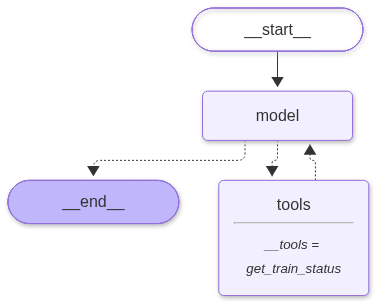

In [9]:
from langchain.agents import create_agent

TRAIN_STATUS = {
    "12951": "Mumbai Rajdhani Express is running on time.",
    "12301": "Howrah Rajdhani Express is delayed by 20 minutes.",
}

def get_train_status(train_number:str)-> str:
    """Get the current status for a train number."""
    if train_number not in TRAIN_STATUS:
        return f"No status found for train number {train_number}."
    return TRAIN_STATUS[train_number]

agent=create_agent(
    model="groq:openai/gpt-oss-20b",
    tools=[get_train_status],
    system_prompt="You are a helpful assistant."
)
agent

In [11]:
### run the agent
response=agent.invoke({"messages":[{"role":"user","content":"What is the status of train number 12951?"}]})

In [12]:
response["messages"]

[HumanMessage(content='What is the status of train number 12951?', additional_kwargs={}, response_metadata={}, id='6a0ec6fc-626e-49b6-b433-d5aa1aab18b9'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'The user wants the status of train number 12951. We have a tool get_train_status. We should call it.', 'tool_calls': [{'id': 'fc_45d84f7e-c8dd-4daa-842c-66cf8b6037ec', 'function': {'arguments': '{"train_number":"12951"}', 'name': 'get_train_status'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 52, 'prompt_tokens': 144, 'total_tokens': 196, 'completion_time': 0.069881523, 'completion_tokens_details': {'reasoning_tokens': 26}, 'prompt_time': 0.016844048, 'prompt_tokens_details': None, 'queue_time': 0.37651582, 'total_time': 0.086725571}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e189667b30', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1fe4a-b5e

In [ ]:
agent.invoke({"messages":"What is the status of train number 99999"})

### 🤔 Before you move on
The agent above only ever talked through `create_agent(...)` — you never touched the plain model underneath it. What if you don't want a full agent yet, just the model itself, so you can invoke it directly, stream its output, or run several prompts at once? That's exactly what `2-modelintegration.ipynb` covers next.